# Curating COCO image-caption pairs

This notebook prepares 1,200 unique COCO images with one cleaned caption per image, using a 1,000/100/100 train/validation/test split. It records the environment, filters captions, preprocesses images and verifies the dataset.


In [1]:
import json
from IPython.display import display
import p2_pipeline as p2
# Record package versions and GPU availability.
environment = p2.check_environment(save_requirements=True)
print(json.dumps(environment, indent=2))
assert environment["ready"], "Environment validation failed; details are recorded above."
config = p2.load_config("config.json")


{
  "utc": "2026-10-25T08:38:24.528870+00:00",
  "python": "3.10.16",
  "python_executable": "/opt/miniconda/envs/eai/bin/python",
  "platform": "Linux-5.14.0-362.13.1.el9_3.x86_64-x86_64-with-glibc2.35",
  "packages": {
    "torch": "2.5.1",
    "diffusers": "0.32.2",
    "transformers": "4.49.0",
    "accelerate": "1.5.2",
    "huggingface-hub": "0.29.3",
    "safetensors": "0.5.3",
    "numpy": "1.26.4",
    "Pillow": "11.1.0",
    "ipykernel": "6.29.5",
    "ipython": "8.34.0",
    "nbconvert": "7.16.6"
  },
  "git_commit": "453f6f78b079ab536a95375c2d4f8b5027f41d46",
  "source_sha256": "fc927d13d1006effe88166bed6bd821f66b662cc3c3e15150590182e8e0fff0b",
  "torch_cuda": "12.1",
  "cudnn": 90100,
  "cuda_available": true,
  "gpu": "Tesla V100-SXM2-32GB",
  "gpu_total_gib": 31.7393798828125,
  "missing_packages": [],
  "import_errors": {},
  "ready": true,
  "requirements_saved": true
}


## Clean captions

Captions are standardized and extra whitespace is removed. Captions outside 5–50 words, containing URLs or email addresses, or exceeding CLIP's token limit are excluded. Duplicate captions are removed regardless of letter case.


## Prepare and verify the subset

Candidates are shuffled with a fixed seed. One eligible caption is selected by annotation ID; images are checked for decoding errors, minimum size and exact pixel duplicates. Splits are assigned after filtering and deduplication. Exact pixel checks do not identify perceptual near duplicates.

Validation pairs are used for the M1 embedding checks and generation examples; the test split is reserved. Completed datasets are verified before reuse.


In [2]:
summary = p2.prepare(config)
display(summary)
# Verify the planned cardinality and image-level split before downstream use.
assert summary["pairs"] == 1200
assert summary["splits"] == {"train": 1000, "validation": 100, "test": 100}
print("Dataset verification passed:", p2.verify_dataset(config)["manifest_sha256"])


{'status': 'complete',
 'config_hash': 'a447141dfe35f1b6edd04087630cfc6ebf9364bdaae12c1750ba3f844b873935',
 'pairs': 1200,
 'splits': {'train': 1000, 'validation': 100, 'test': 100},
 'rejected_images': 0,
 'category_image_counts': {'person': 662,
  'tennis racket': 49,
  'dining table': 119,
  'sandwich': 20,
  'car': 120,
  'skateboard': 30,
  'traffic light': 41,
  'bottle': 90,
  'motorcycle': 32,
  'truck': 59,
  'book': 67,
  'cup': 89,
  'keyboard': 26,
  'laptop': 55,
  'mouse': 26,
  'bird': 29,
  'chair': 148,
  'couch': 55,
  'microwave': 17,
  'refrigerator': 29,
  'sink': 38,
  'tv': 67,
  'sports ball': 46,
  'clock': 48,
  'backpack': 50,
  'handbag': 76,
  'stop sign': 15,
  'fire hydrant': 17,
  'toilet': 38,
  'bench': 57,
  'umbrella': 40,
  'banana': 15,
  'bowl': 70,
  'fork': 43,
  'knife': 42,
  'spoon': 35,
  'tie': 35,
  'bus': 54,
  'vase': 31,
  'giraffe': 28,
  'snowboard': 15,
  'skis': 30,
  'remote': 40,
  'cell phone': 46,
  'train': 43,
  'cake': 24,
  

Dataset verification passed: b6683d25acda660cce6a95e049b6561f515f08a9ad072e8c260cf75e10759de8


## Inspect examples and coverage

Images are converted to RGB, resized with preserved aspect ratio and gray padding to 512 x 512 pixels. Category counts overlap because one image may contain several categories. Each image retains its source and license records.


Category image counts: {'person': 662, 'tennis racket': 49, 'dining table': 119, 'sandwich': 20, 'car': 120, 'skateboard': 30, 'traffic light': 41, 'bottle': 90, 'motorcycle': 32, 'truck': 59, 'book': 67, 'cup': 89, 'keyboard': 26, 'laptop': 55, 'mouse': 26, 'bird': 29, 'chair': 148, 'couch': 55, 'microwave': 17, 'refrigerator': 29, 'sink': 38, 'tv': 67, 'sports ball': 46, 'clock': 48, 'backpack': 50, 'handbag': 76, 'stop sign': 15, 'fire hydrant': 17, 'toilet': 38, 'bench': 57, 'umbrella': 40, 'banana': 15, 'bowl': 70, 'fork': 43, 'knife': 42, 'spoon': 35, 'tie': 35, 'bus': 54, 'vase': 31, 'giraffe': 28, 'snowboard': 15, 'skis': 30, 'remote': 40, 'cell phone': 46, 'train': 43, 'cake': 24, 'surfboard': 39, 'donut': 11, 'oven': 26, 'wine glass': 23, 'horse': 24, 'cow': 20, 'zebra': 19, 'broccoli': 24, 'teddy bear': 26, 'sheep': 16, 'baseball bat': 19, 'cat': 41, 'pizza': 39, 'boat': 34, 'suitcase': 24, 'dog': 43, 'airplane': 16, 'baseball glove': 18, 'bed': 27, 'carrot': 19, 'elephant':

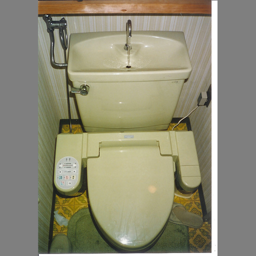

519491 A tall clock tower with a statue on top. {'url': 'http://creativecommons.org/licenses/by-nc-nd/2.0/', 'id': 3, 'name': 'Attribution-NonCommercial-NoDerivs License'}


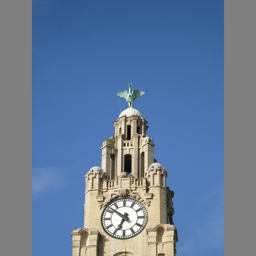

61584 a couple is sitting on a statue of a horse and some plants {'url': 'http://creativecommons.org/licenses/by/2.0/', 'id': 4, 'name': 'Attribution License'}


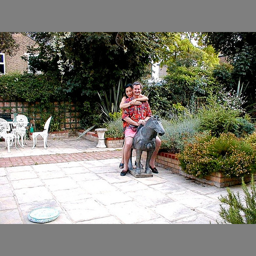

486040 Two desktop computers sitting on top of a desk. {'url': 'http://creativecommons.org/licenses/by-nc-sa/2.0/', 'id': 1, 'name': 'Attribution-NonCommercial-ShareAlike License'}


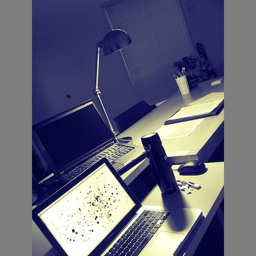

In [3]:
rows = p2.manifest(config)
print("Category image counts:", summary["category_image_counts"])
print("License image counts:", summary["license_image_counts"])
for row in [r for r in rows if r["split"] == "validation"][:4]:
    print(row["image_id"], row["caption"], row["license"])
    with p2.Image.open(p2.local_path(config, "dataset_dir") / row["image_path"]) as image:
        display(image.resize((256, 256)))


## Check normalization

`normalized_pixels` converts RGB values from [0, 255] to CHW float32 arrays in [-1, 1]. CLIP uses its own pretrained processor. Text-to-image generation takes captions and latent noise; reference images are used for comparison.


In [4]:
with p2.Image.open(p2.local_path(config, "dataset_dir") / rows[0]["image_path"]) as image:
    values = p2.normalized_pixels(image)
print(values.shape, values.dtype, float(values.min()), float(values.max()))
assert values.shape == (3, 512, 512)
assert -1 <= values.min() <= values.max() <= 1


(3, 512, 512) float32 -1.0 1.0


## Dataset files

Dataset records are saved in `manifest.jsonl`, and dataset statistics are saved in `dataset_summary.json`.
